# Chapter 10 · Project: one twin, three kinds of sensor (Gothenburg, summer 2015)
**Level: Expert** · ~40 min to read · first run ~40 min, then cached · 2D · *Applied project, part 4*

Chapters 8 and 9 used links only, on 8 days. Here the twin gets the whole summer of 2015 and
every sensor Gothenburg has:

| letter | sensor | what it sees | count |
|---|---|---|---|
| **L** | commercial microwave links | path-averaged rain, from FieldSense's RNN retrieval | 358 |
| **P** | personal weather stations (Netatmo), after quality control | rain in a bucket | 27 cells |
| **R** | SMHI C-band radar | rain rate on 2 km cells, every 5 min | 1540 cells |
| | 10 city gauges | **never assimilated**: they only score | 10 |

All of it comes from the 5-minute data cube that FieldSense's `multisensor_nowcasting` project
builds, read by `raintwin.cube.Cube`. That project's sister study (`multisensor_maps`) already
answered "what is the best *static* map from these sensors": the radar adjusted by the
residuals at links and stations, product **RCP**. It is the benchmark here, scored on the
same 10 storms (FieldSense's study storms, all in the test weeks) with the same rule: hourly
NRMSE at the 10 city gauges, RMSE divided by the mean gauge rain.

**Questions**
1. Which sensor mix gives the twin its best map, and does the twin beat the static merge?
2. What goes wrong when a smooth twin meets a sharp radar, and how should the radar enter?
3. What does a twin give that a static map does not?

In [1]:
import sys, time, pickle; sys.path.insert(0, "..")
from pathlib import Path
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dtwin import viz
from raintwin import system
from raintwin.cube import Cube
viz.set_style()

CACHE = Path("../cache"); CACHE.mkdir(exist_ok=True)
c = Cube("openmrg")
EVENTS = c.events()
GI = np.round(c.gauges["y"] / c.dx).astype(int), np.round(c.gauges["x"] / c.dx).astype(int)
print(f"{len(c.times)} steps of 5 min, {c.y.size} x {c.x.size} cells of {c.dx:.0f} km")
print(f"{len(c.link_id)} links, {len(c.pws['x'])} station cells, {len(c.gauges['id'])} city gauges")
print("split of the summer (train / validation / test steps):", np.bincount(c.split))
for name, s, e in EVENTS:
    print(f"  {name}: {s:%d %b %H:%M} to {e:%d %b %H:%M}, split {set(c.split[c.index(s, e)])}")

26496 steps of 5 min, 44 x 35 cells of 2 km
358 links, 27 station cells, 10 city gauges
split of the summer (train / validation / test steps): [ 9996  4944 11556]
  20150602T04: 02 Jun 04:00 to 03 Jun 10:00, split {np.int64(2)}
  20150707T17: 07 Jul 17:00 to 09 Jul 09:00, split {np.int64(2)}
  20150719T14: 19 Jul 14:00 to 20 Jul 01:00, split {np.int64(2)}
  20150725T05: 25 Jul 05:00 to 25 Jul 15:00, split {np.int64(2)}
  20150725T21: 25 Jul 21:00 to 26 Jul 07:00, split {np.int64(2)}
  20150728T03: 28 Jul 03:00 to 29 Jul 11:00, split {np.int64(2)}
  20150804T19: 04 Aug 19:00 to 05 Aug 01:00, split {np.int64(2)}
  20150825T02: 25 Aug 02:00 to 25 Aug 23:00, split {np.int64(2)}
  20150827T01: 27 Aug 01:00 to 28 Aug 01:00, split {np.int64(2)}
  20150831T17: 31 Aug 17:00 to 01 Sep 00:00, split {np.int64(2)}


## 1. The network

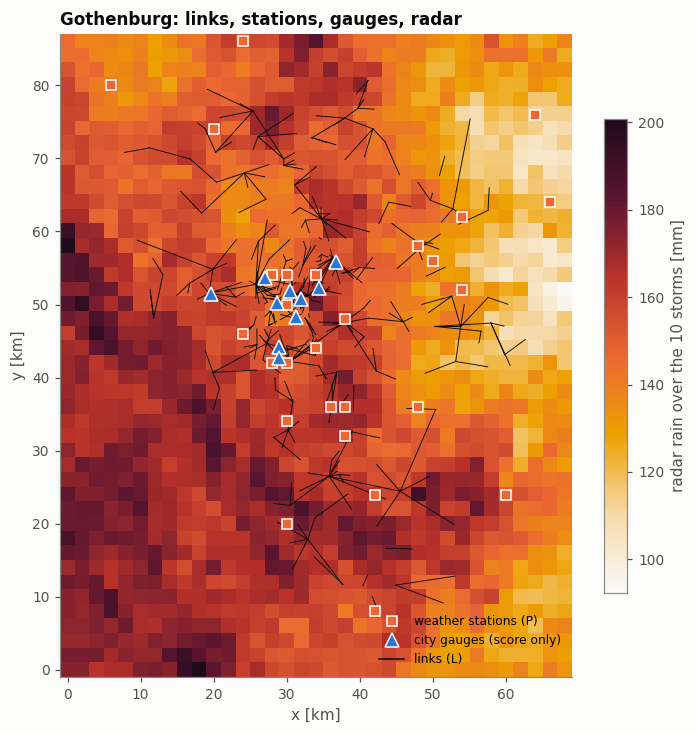

In [2]:
tot = sum(np.nansum(c.radar(c.index(s, e)), 0) for _, s, e in EVENTS) / 12
ext = (-1, c.x[-1] + 1, -1, c.y[-1] + 1)
fig, ax = plt.subplots(figsize=(7.5, 8))
ax.grid(False)
im = ax.imshow(tot, origin="lower", cmap=viz.FIELD, extent=ext)
plt.colorbar(im, ax=ax, shrink=0.7, label="radar rain over the 10 storms [mm]")
L = c.links
for i in range(L["xa"].size):
    ax.plot([L["xa"][i], L["xb"][i]], [L["ya"][i], L["yb"][i]], color=viz.INK, lw=0.6)
ax.plot(c.pws["x"], c.pws["y"], "s", color=viz.ORANGE, ms=6, mec="white", label="weather stations (P)")
ax.plot(c.gauges["x"], c.gauges["y"], "^", color=viz.BLUE, ms=9, mec="white", label="city gauges (score only)")
ax.plot([], [], color=viz.INK, lw=1, label="links (L)")
ax.set(xlabel="x [km]", ylabel="y [km]", title="Gothenburg: links, stations, gauges, radar")
ax.legend(loc="lower right", fontsize=8)
viz.save(fig, "10_network.png")
plt.show()

The links and gauges sit in the city; the stations are spread a bit wider; the radar covers
everything. Every gauge is within a few km of a link, so near-link accuracy is what the score
rewards.

## 2. Scoring rule and the static benchmark
Each map is read at the gauge's cell, summed to hourly rain, and compared with the gauge.
FieldSense's cube stores its static maps for every step, so they can be scored first:
**R** radar, **C** link IDW, **P** station IDW, **CP** both, and the radar adjusted by the
misses at links (**RC**), stations (**RP**) or both (**RCP**).

In [3]:
SPIN = 12                                                     # one hour of spin-up before a storm
steps = [c.index(s - pd.Timedelta("1h"), e) for _, s, e in EVENTS]
scored = np.concatenate([st[SPIN:] for st in steps])
G = c.gauge_rain(scored)
HOURS = c.times[scored].ceil("h")


def hourly(a):
    return pd.DataFrame(a / 12, index=HOURS).groupby(level=0).sum(min_count=12).values


GH = hourly(G)


def score(E):
    """Hourly NRMSE, hourly correlation and relative bias at the gauges; 5-min correlation."""
    Eh = hourly(E)
    ok, ok5 = np.isfinite(Eh) & np.isfinite(GH), np.isfinite(E) & np.isfinite(G)
    return dict(nrmse=np.sqrt(np.mean((Eh[ok] - GH[ok]) ** 2)) / GH[ok].mean(),
                corr=np.corrcoef(Eh[ok], GH[ok])[0, 1], bias=Eh[ok].mean() / GH[ok].mean() - 1,
                corr5=np.corrcoef(E[ok5], G[ok5])[0, 1])


table = {}
for p in ("R", "C", "P", "CP", "RC", "RP", "RCP"):
    table["static " + p] = score(c.product(p, scored)[:, GI[0], GI[1]])
print(pd.DataFrame(table).T.round(2))

            nrmse  corr  bias  corr5
static R     1.47  0.71 -0.02   0.40
static C     1.07  0.84  0.05   0.72
static P     1.13  0.83 -0.18   0.55
static CP    1.06  0.84  0.05   0.72
static RC    1.02  0.86  0.07   0.72
static RP    1.17  0.81 -0.06   0.47
static RCP   0.99  0.87  0.06   0.72


The radar alone is the worst map at the gauges (NRMSE 1.47; FieldSense's report has the same
number). Links alone are much better (1.07). The radar adjusted with links and stations is
the best, **0.99**. That is the bar.

## 3. The twin with every sensor mix
`raintwin.system.run(cube, steps, "LPR")` builds one `RainTwin` on the cube grid and adds an
observation set for each letter:

* **L**: path averages of rain, error 0.3 mm/h + 15 %.
* **P**: point readings in the station's cell, error 0.5 mm/h + 30 % (buckets under trees,
  on balconies).
* **R**: every other radar cell, observed **in log space**: the radar reading becomes
  log(R + 1) and is compared with the twin's own log state. That observation is linear in the
  state, so the Kalman update is exact for it. When the radar is not the only sensor, its
  bias is a state parameter too.

Three settings changed from Chapter 8, each for a reason found on these storms:
* The log offset r0 is 1 mm/h instead of 0.1. With 0.1, members near zero rain have almost no
  spread in rain units, so a link reading 5 mm/h barely moves them, and a storm that starts dry
  is never picked up (NRMSE 2.97 for links only).
* The speed is capped at 60 km/h. Without the cap the velocity, updated by hundreds of
  observations without localization, sometimes ran off.
* Radar in rain space (error 1 mm/h + 50 %) left the radar-only twin 40 % low and made one storm
  overshoot; the log-space observation fixes the overshoot.

Every run also makes the **now map** of Chapter 9: the twin mean plus a 3 km IDW of what it
misses at the links and stations.

The ten storms times six mixes take about 35 minutes, so the results are cached.

In [4]:
CONFIGS = ["L", "P", "R", "LR", "LPR"]
FIG_EVENT = "20150728T03"


def run_all():
    out = {}
    for cf in CONFIGS + ["E:LP"]:
        t0 = time.time()
        g_mean, g_now, vel, maps = [], [], [], None
        for (name, _, _), st in zip(EVENTS, steps):
            o = system.run_error_twin(c, st, "LP") if cf == "E:LP" else system.run(c, st, cf)
            g_mean.append(o["mean"][SPIN:][:, GI[0], GI[1]]); g_now.append(o["now"][SPIN:][:, GI[0], GI[1]])
            vel.append(o["V"])
            if name == FIG_EVENT and cf in ("LPR", "E:LP"):
                maps = {k: o[k].astype("float32") for k in o if k != "V"}
        out[cf] = dict(mean=np.concatenate(g_mean), now=np.concatenate(g_now), V=vel, maps=maps,
                       seconds=time.time() - t0)
        print(f"{cf:5s}: {time.time() - t0:5.0f}s")
    return out


f = CACHE / "ch10_runs.pkl"
if f.exists():
    runs = pickle.load(open(f, "rb"))
else:
    runs = run_all()
    pickle.dump(runs, open(f, "wb"))
for cf, r in runs.items():
    table[f"twin {cf} (mean)"] = score(r["mean"])
    table[f"twin {cf} (now map)"] = score(r["now"])
T = pd.DataFrame(table).T
print(T.round(2).to_string())

                     nrmse  corr  bias  corr5
static R              1.47  0.71 -0.02   0.40
static C              1.07  0.84  0.05   0.72
static P              1.13  0.83 -0.18   0.55
static CP             1.06  0.84  0.05   0.72
static RC             1.02  0.86  0.07   0.72
static RP             1.17  0.81 -0.06   0.47
static RCP            0.99  0.87  0.06   0.72
twin L (mean)         1.15  0.81 -0.08   0.65
twin L (now map)      1.05  0.85  0.05   0.73
twin P (mean)         1.77  0.66 -0.60   0.46
twin P (now map)      1.32  0.75 -0.22   0.44
twin R (mean)         1.51  0.65 -0.21   0.47
twin R (now map)      1.51  0.65 -0.21   0.47
twin LR (mean)        1.14  0.82 -0.08   0.66
twin LR (now map)     1.05  0.85  0.05   0.73
twin LPR (mean)       1.26  0.78 -0.03   0.60
twin LPR (now map)    1.06  0.84  0.01   0.69
twin E:LP (mean)      1.21  0.79 -0.08   0.60
twin E:LP (now map)   1.08  0.84  0.02   0.68


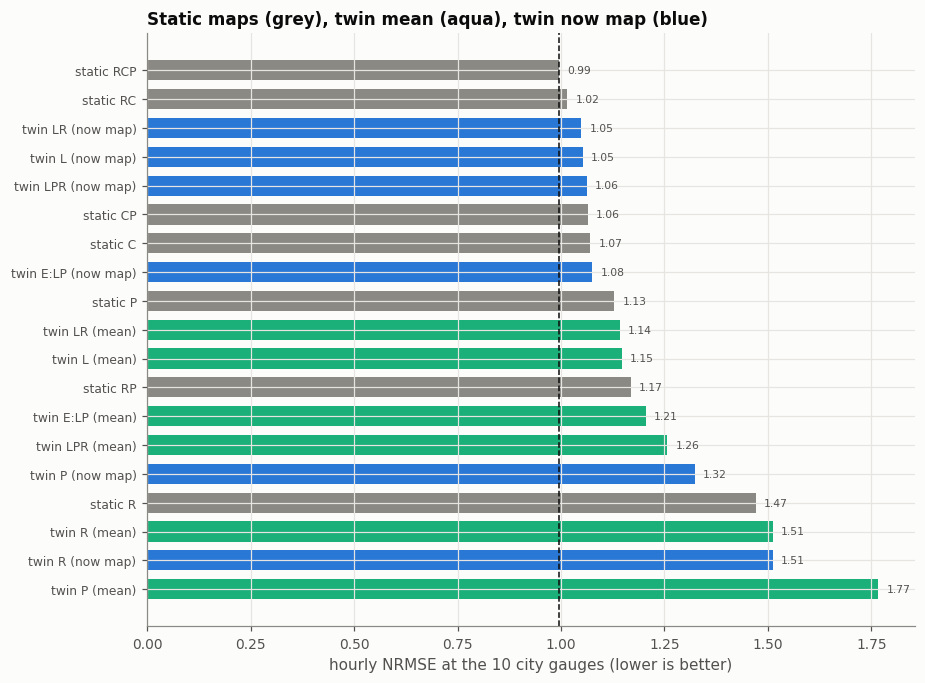

In [5]:
order = T.sort_values("nrmse")
fig, ax = plt.subplots(figsize=(9, 7))
cols = [viz.MUTED if k.startswith("static") else (viz.TWIN if "now" in k else viz.AQUA) for k in order.index]
ax.barh(range(len(order)), order.nrmse, color=cols, height=0.7)
ax.set_yticks(range(len(order)), order.index, fontsize=8)
ax.invert_yaxis()
ax.axvline(T.loc["static RCP", "nrmse"], color=viz.INK, lw=1, ls="--")
for i, v in enumerate(order.nrmse):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=7, color=viz.INK2)
ax.set(xlabel="hourly NRMSE at the 10 city gauges (lower is better)",
       title="Static maps (grey), twin mean (aqua), twin now map (blue)")
viz.save(fig, "10_scores.png")
plt.show()

**Reading the table.**
* The best twin maps are the now maps with links: about **1.05**. That beats every static map
  that does not use the radar (link IDW 1.07, links + stations 1.06), and loses to the static
  radar merges (RC 1.02, RCP 0.99).
* The twin mean on its own is worse (1.15 with links). It is smooth: 40 members with 6 km noise
  cannot hold a 2 km convective cell. The now map's local correction puts the cells back.
* Stations are weak in this twin. Alone, the twin mean is 60 % low at the gauges, because
  between the 27 station cells it falls back to the background. Added to links they do not
  help.
* The radar helps the twin little. Section 4 shows why.

### Storm by storm: where does the merge win?
One score over ten storms hides how the storms differ. Below, the score of each storm on its
own, for link IDW, the static merge RCP and the links-only twin, plus each storm's share of
the gap between the twin and RCP in squared error (the sum that NRMSE is made of).

In [6]:
STORM_H = pd.Series(np.concatenate([np.full(st.size - SPIN, i) for i, st in enumerate(steps)]),
                    index=HOURS).groupby(level=0).first().values
per_storm = {"static C": c.product("C", scored)[:, GI[0], GI[1]],
             "static RCP": c.product("RCP", scored)[:, GI[0], GI[1]],
             "twin L (now map)": runs["L"]["now"]}
per_storm = {k: hourly(v) for k, v in per_storm.items()}


def storm_nrmse(Eh, s):
    m = STORM_H == s
    ok = np.isfinite(Eh[m]) & np.isfinite(GH[m])
    return np.sqrt(np.mean((Eh[m][ok] - GH[m][ok]) ** 2)) / GH[m][ok].mean()


def storm_sse(Eh, s):
    m = STORM_H == s
    return np.nansum((Eh[m] - GH[m]) ** 2)


PS = pd.DataFrame({k: [storm_nrmse(v, s) for s in range(len(EVENTS))] for k, v in per_storm.items()},
                  index=[n for n, _, _ in EVENTS])
PS.insert(0, "hours", [int((STORM_H == s).sum()) for s in range(len(EVENTS))])
gap = np.array([storm_sse(per_storm["twin L (now map)"], s) - storm_sse(per_storm["static RCP"], s)
                for s in range(len(EVENTS))])
PS["share of gap"] = gap / gap.sum()
print(PS.round(2).to_string())
print(f"\nRCP better than the twin in {(PS['static RCP'] < PS['twin L (now map)']).sum()} of {len(PS)} storms; "
      f"the two largest shares of the gap add up to {np.sort(PS['share of gap'])[-2:].sum():.0%}")

             hours  static C  static RCP  twin L (now map)  share of gap
20150602T04     31      1.18        0.98              1.19          0.41
20150707T17     41      1.14        1.09              1.12          0.04
20150719T14     12      0.83        0.84              0.81         -0.00
20150725T05     11      0.68        0.68              0.69          0.00
20150725T21     11      1.34        1.30              1.31          0.02
20150728T03     33      1.67        1.51              1.62          0.37
20150804T19      7      0.84        1.01              0.87          0.05
20150825T02     22      0.59        0.56              0.54         -0.02
20150827T01     25      0.79        0.69              0.79          0.13
20150831T17      8      0.45        0.42              0.44          0.01

RCP better than the twin in 7 of 10 storms; the two largest shares of the gap add up to 78%


* RCP is better than the twin in most storms, but in most of them only by a hair.
* Nearly 80 % of RCP's lead comes from **two storms**, 2 June and 28 July (about 30 hours
  each). They are neither the most intense (the end of August has higher rates) nor the
  longest (7 July lasts 41 hours and adds almost nothing to the gap). What sets them apart is
  an open question (exercise: map where RCP and the twin differ most in those two storms).
* So "the merge beats the twin" is mostly a statement about those two storms. With ten storms,
  one or two of them can decide the table; the bootstrap in `tools/extend_runs.py A` puts a
  95 % range of about 0.75 to 1.3 on every map's total score, while the *paired* difference
  twin minus RCP stays between about 0.0 and 0.11.

## 4. A smooth twin and a sharp radar
The radar has the structure the twin lacks, but the twin can only hold a smooth version of it.
On the heaviest hour of 28 July:

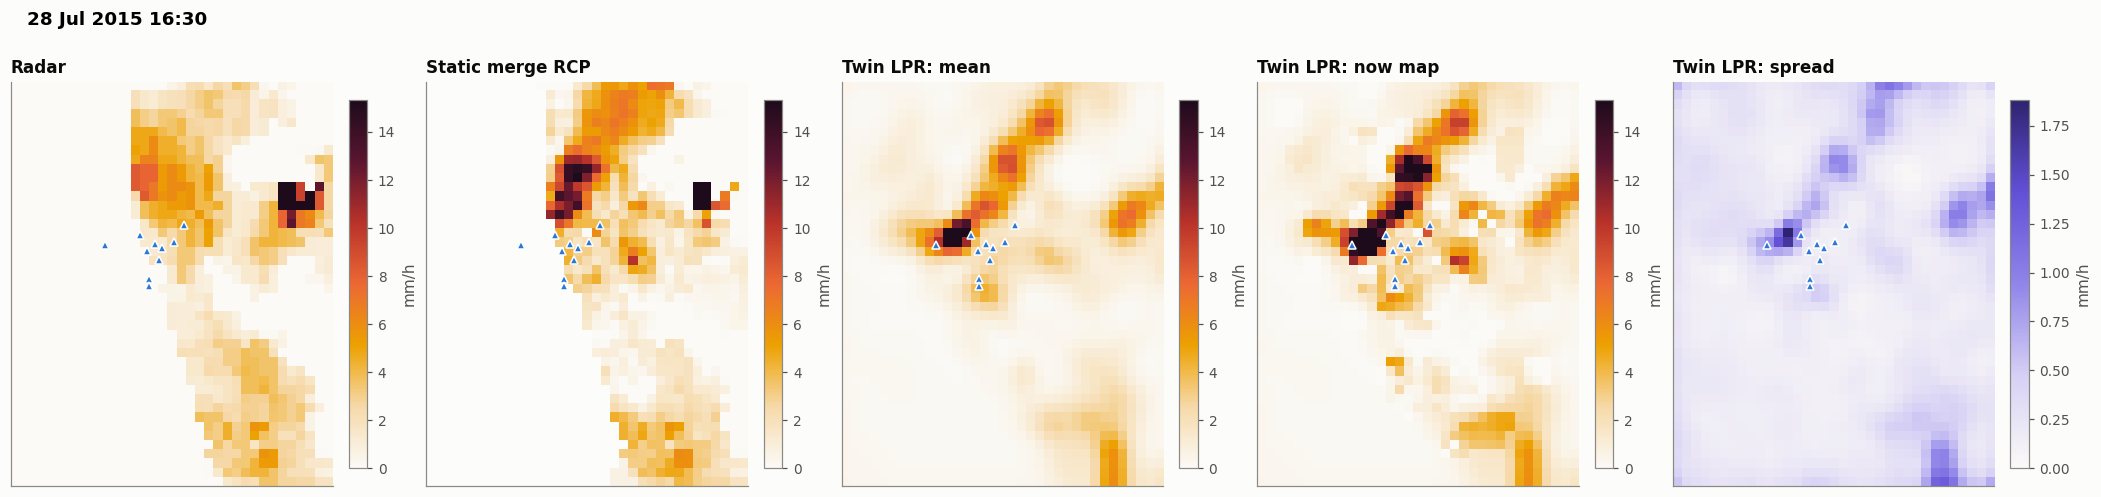

peak rain: radar 59.2, RCP 44.8, twin mean 24.5, now map 38.8 mm/h


In [7]:
r = runs["LPR"]["maps"]
fe = [i for i, (n, _, _) in enumerate(EVENTS) if n == FIG_EVENT][0]
st = steps[fe]
k = int(np.nanargmax(np.nanmean(c.radar(st), (1, 2))))
fields = [(np.nan_to_num(c.radar(st[[k]])[0]), "Radar", viz.FIELD),
          (c.product("RCP", st[[k]])[0], "Static merge RCP", viz.FIELD),
          (r["mean"][k], "Twin LPR: mean", viz.FIELD),
          (r["now"][k], "Twin LPR: now map", viz.FIELD),
          (r["spread"][k], "Twin LPR: spread", viz.UNCERTAINTY)]
vm = np.nanpercentile(fields[0][0], 99.5)
fig, axes = plt.subplots(1, 5, figsize=(19, 4.8), constrained_layout=True)
for ax, (F, ttl, cm) in zip(axes, fields):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=cm, vmin=0, vmax=vm if cm is viz.FIELD else None, extent=ext)
    ax.plot(c.gauges["x"], c.gauges["y"], "^", color=viz.BLUE, ms=5, mec="white")
    ax.set(title=ttl, xticks=[], yticks=[])
    plt.colorbar(im, ax=ax, shrink=0.75, label="mm/h")
fig.suptitle(f"{c.times[st[k]]:%d %b %Y %H:%M}", x=0.01, ha="left", fontweight="semibold")
viz.save(fig, "10_maps.png")
plt.show()
print(f"peak rain: radar {np.nanmax(fields[0][0]):.1f}, RCP {np.nanmax(fields[1][0]):.1f}, "
      f"twin mean {np.nanmax(fields[2][0]):.1f}, now map {np.nanmax(fields[3][0]):.1f} mm/h")

The twin keeps the shape of the storm and loses more than half of the peak; the now map gets
some of it back near the links. That is the price of a
filter built on a 40-member ensemble with a smooth noise model: it can only represent what its
ensemble spans.

**A different design: twin the radar's error, not the rain.** `RadarErrorTwin` keeps the radar
as the detailed picture and makes its *correction* the state:

$$R(x,t) = \big(R_\text{radar}(x,t) + 0.5\big)\,e^{z(x,t)} - 0.5$$

The state z is a smooth log-factor, moved with the storm, relaxing back to zero over 3 hours,
and corrected by the links and stations. This is the static merge made dynamic: the correction
found an hour ago is carried along instead of forgotten. In the table it is `twin E:LP`.

twin E:LP (mean)       NRMSE 1.21   corr 0.79   bias -8%
twin E:LP (now map)    NRMSE 1.08   corr 0.84   bias +2%
twin LPR (now map)     NRMSE 1.06   corr 0.84   bias +1%
static RCP             NRMSE 0.99   corr 0.87   bias +6%
static RC              NRMSE 1.02   corr 0.86   bias +7%


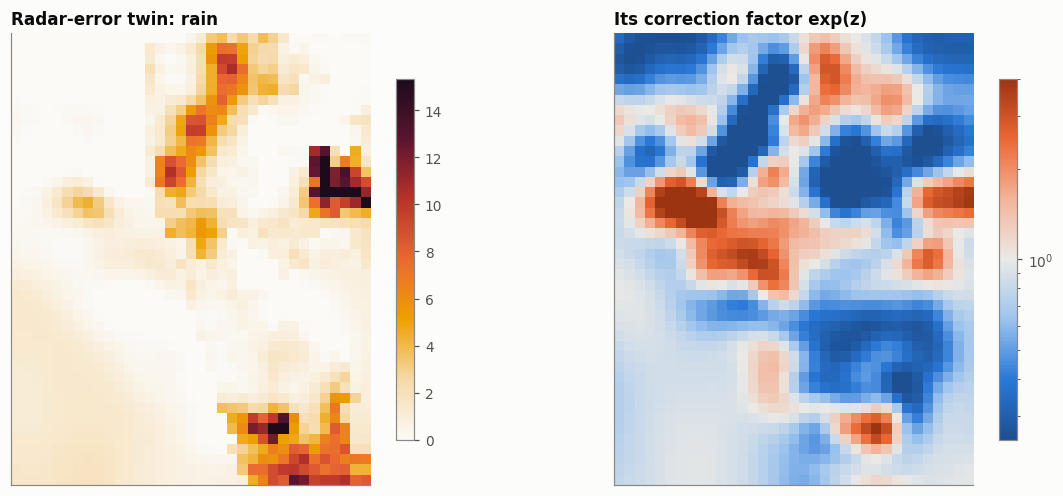

In [8]:
for key in ("twin E:LP (mean)", "twin E:LP (now map)", "twin LPR (now map)", "static RCP", "static RC"):
    print(f"{key:22s} NRMSE {T.loc[key, 'nrmse']:.2f}   corr {T.loc[key, 'corr']:.2f}   "
          f"bias {T.loc[key, 'bias']:+.0%}")
fac = runs["E:LP"]["maps"]["factor"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
for ax, (F, ttl) in zip(axes, [(runs["E:LP"]["maps"]["mean"][k], "Radar-error twin: rain"),
                               (fac[k], "Its correction factor exp(z)")]):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=viz.FIELD if "rain" in ttl else viz.DIVERGING,
                   vmin=0 if "rain" in ttl else 0.25, vmax=vm if "rain" in ttl else 4.0, extent=ext)
    if "factor" in ttl:
        im.set_norm(plt.matplotlib.colors.LogNorm(0.25, 4.0))
    ax.set(title=ttl, xticks=[], yticks=[])
    plt.colorbar(im, ax=ax, shrink=0.8)
viz.save(fig, "10_error_twin.png")
plt.show()

The radar-error twin keeps the radar's peaks, and its now map scores about like the rain twin's,
still behind the static merge. On these storms the extra machinery buys no accuracy *at the
gauges* over FieldSense's static RCP.

## 5. What the twin adds that a static map cannot
Accuracy at 10 gauges is only one column. Two others:

**Motion.** Every twin learns the storm velocity from its sensors. Compare with the motion of the
radar itself (phase correlation of frames 30 minutes apart, in 4 km/h steps):

In [9]:
def radar_motion(F, lag=6):
    F = np.nan_to_num(F); F = F - F.mean((1, 2), keepdims=True)
    acc = 0
    for a, b in zip(F[:-lag], F[lag:]):
        A, B = np.fft.fft2(a), np.fft.fft2(b)
        acc = acc + B * np.conj(A)
    cc = np.real(np.fft.ifft2(acc / (np.abs(acc) + 1e-9)))
    iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    ny, nx = cc.shape
    return np.array([ix if ix <= nx // 2 else ix - nx, iy if iy <= ny // 2 else iy - ny]) * c.dx / (lag * 5 / 60)


print(f"{'storm':12s} {'radar':>12s} {'twin L':>12s} {'twin LPR':>12s}")
mot = []
for j, ((name, _, _), st) in enumerate(zip(EVENTS, steps)):
    vr = radar_motion(c.radar(st))
    vl = runs["L"]["V"][j][len(st) // 2:].mean(0)
    va = runs["LPR"]["V"][j][len(st) // 2:].mean(0)
    mot.append((vr, vl, va))
    print(f"{name:12s} {str(vr.round(0)):>12s} {str(vl.round(0)):>12s} {str(va.round(0)):>12s}")
mot = np.array(mot)
moving = np.hypot(*mot[:, 0].T) > 0                 # storms where the radar shows a shift
print(f"{moving.sum()} storms with a measurable radar motion:")
for j, lab in ((1, "twin L"), (2, "twin LPR")):
    m_ = mot[moving]
    ang = np.degrees(np.arctan2(m_[:, j, 1], m_[:, j, 0]) - np.arctan2(m_[:, 0, 1], m_[:, 0, 0]))
    ang = (ang + 180) % 360 - 180
    print(f"  {lab}: median direction error {np.median(np.abs(ang)):.0f} degrees, "
          f"median speed ratio {np.median(np.hypot(*m_[:, j].T) / np.hypot(*m_[:, 0].T)):.2f}")

storm               radar       twin L     twin LPR
20150602T04     [68. 16.]  [-12.  -6.]    [21. 16.]


20150707T17     [44.  0.]    [39.  9.]    [32. 21.]
20150719T14     [12. 12.]    [11.  5.]    [10. 10.]
20150725T05     [ 0. 24.]    [-1.  0.]    [ 8. 15.]
20150725T21     [-4. 32.]    [-3. 17.]    [ 1. 19.]


20150728T03     [ 8. 16.]    [ 1. 14.]    [ 1. 13.]
20150804T19   [ 40. -28.]      [7. 7.]    [ 0. 17.]
20150825T02       [0. 0.]    [12. 12.]    [ 7. 25.]
20150827T01     [48. 28.]    [-1. 10.]    [37. 19.]


20150831T17       [0. 0.]    [-4.  5.]    [20. 12.]
8 storms with a measurable radar motion:
  twin L: median direction error 45 degrees, median speed ratio 0.37
  twin LPR: median direction error 22 degrees, median speed ratio 0.70


With the radar in the state the twin's motion is closer to the radar's, in direction and speed.
With links only the direction is often far off and the speed too low: a network 30 km across
sees a storm for only an hour, and the filter is slow to move its velocity. Both twins are
slower than the radar's estimate, which itself comes in coarse 4 km/h steps.

**Uncertainty.** The twin gives a spread with every map. Is it honest? If it were, about 95 %
of gauge readings would fall within the twin mean ± 2 spreads.

In [10]:
sp = np.concatenate([runs["LPR"]["maps"]["spread"][SPIN:][:, GI[0], GI[1]]])
mn = runs["LPR"]["maps"]["mean"][SPIN:][:, GI[0], GI[1]]
g = c.gauge_rain(steps[fe][SPIN:])
ok = np.isfinite(g) & (g > 0.1)
print(f"28 July, wet 5-min steps: {np.mean(np.abs(g[ok] - mn[ok]) <= 2 * sp[ok]):.0%} of gauge readings "
      f"inside mean ± 2 spread (95 % if the spread were right)")

28 July, wet 5-min steps: 15% of gauge readings inside mean ± 2 spread (95 % if the spread were right)


The spread is far too small. An ensemble of 40 members spans only the errors its noise model
allows, and that model was set for the sensors, not for a gauge 1 km from the nearest link,
where sub-cell rain variability dominates. It is still useful as a *relative* map (it is large where no sensor
looks and during heavy rain), and Chapter 11 shows it can be learned too.

## Conclusions
| | result on the 10 storms |
|---|---|
| best static map (FieldSense RCP) | NRMSE 0.99 |
| best twin map (now map, links in the state) | about 1.05, better than any static map without radar |
| twin mean alone | 1.15 or worse: too smooth for convective cells |
| radar in the twin | in log space, or as the base of a radar-error twin; neither beats RCP at the gauges |
| motion | learned; closer to the radar's when the radar is in the state |
| spread | far too narrow in absolute terms (15 % coverage where 95 % is expected, 28 July) |

So the twin is not the best *map maker* when a good radar merge is available. It is a
**system**: one state that takes any sensor, holds motion and uncertainty, and runs through
time. That makes it a good *teacher*. Chapter 11 distils it into a network that needs no radar
and makes a map in two milliseconds.